# Task 3 — Distributions and relationships

This notebook uses the penguins dataset. The main lesson is that grouping matters: a relationship across all penguins can reverse when broken down by species.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

path = Path('data') / 'penguins.csv'
df = pd.read_csv(path)
print(df.isna().sum())
print('Rows with missing values:', df.isna().any(axis=1).sum())
df.head()


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
Rows with missing values: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## 1) Handle missing values
There are missing values in measurements and in sex. For charts about body mass and bill dimensions, I will drop rows with missing values in those variables. For species-by-sex comparisons, I will also drop rows with missing sex. This keeps the analysis honest without inventing values.


In [2]:
clean = df.dropna(subset=['body_mass_g', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm']).copy()
sex_clean = clean.dropna(subset=['sex']).copy()
clean.shape, sex_clean.shape


((342, 7), (333, 7))

## 2) Distribution of body mass
The overall distribution is a single hump but with species-level differences underneath it.

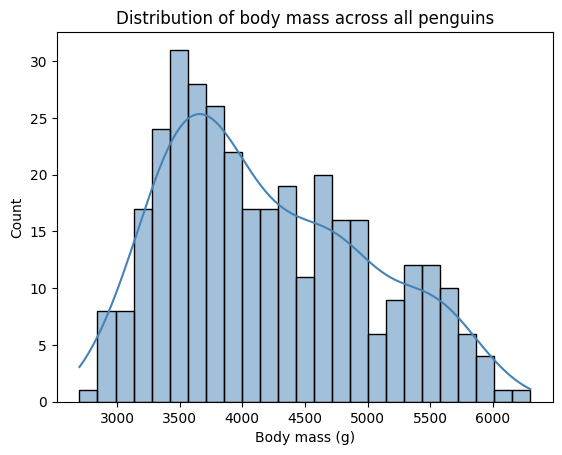

In [3]:
sns.histplot(data=clean, x='body_mass_g', bins=25, kde=True, color='steelblue')
plt.title('Distribution of body mass across all penguins')
plt.xlabel('Body mass (g)')
plt.ylabel('Count')
plt.show()


## 3) Distribution by species
When we split by species, the shape becomes clearer.

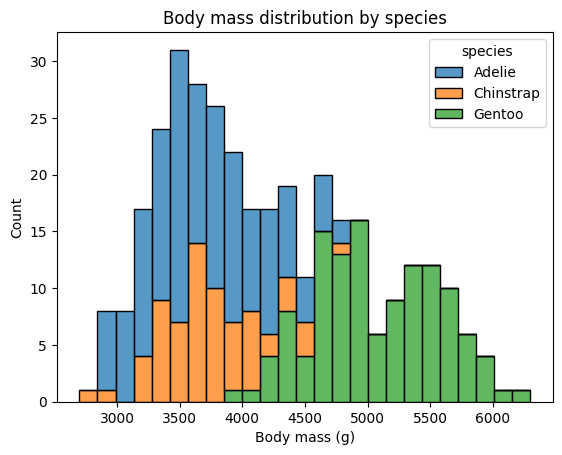

In [4]:
sns.histplot(data=clean, x='body_mass_g', hue='species', multiple='stack', bins=25)
plt.title('Body mass distribution by species')
plt.xlabel('Body mass (g)')
plt.ylabel('Count')
plt.show()


## 4) Scatter plot: bill length vs bill depth
Across all penguins, the relationship looks negative; within each species it is positive. This is Simpson's paradox.


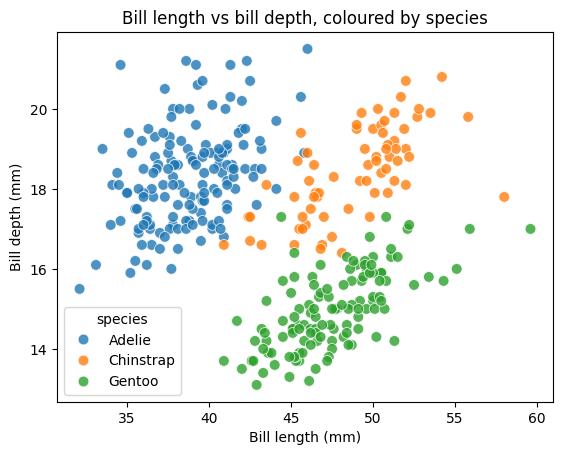

In [5]:
sns.scatterplot(data=clean, x='bill_length_mm', y='bill_depth_mm', hue='species', s=60, alpha=0.8)
plt.title('Bill length vs bill depth, coloured by species')
plt.xlabel('Bill length (mm)')
plt.ylabel('Bill depth (mm)')
plt.show()


The species are different in both average bill size and average bill depth. Because species are mixed together, the overall trend is dominated by between-species differences rather than the within-species pattern.


## 5) Average body mass by species and sex
This chart makes the group differences explicit.

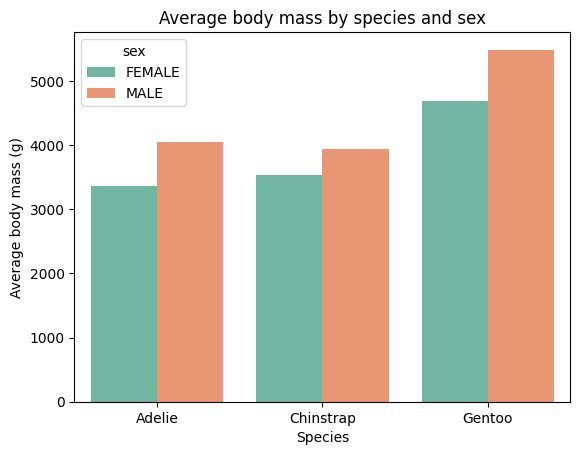

In [6]:
species_sex = sex_clean.groupby(['species', 'sex'], as_index=False)['body_mass_g'].mean()

sns.barplot(data=species_sex, x='species', y='body_mass_g', hue='sex', palette='Set2')
plt.title('Average body mass by species and sex')
plt.xlabel('Species')
plt.ylabel('Average body mass (g)')
plt.show()


This task is an excellent example of why visualizing grouped data matters. If you collapse the species together, you can easily draw the wrong conclusion.
